# PROJECT 1 — NETFLIX: Content Catalog Health Audit
### Domain: Media & Entertainment (OTT / Streaming) &nbsp;|&nbsp; Level: **BASIC**

---

## 1. The Real-World Problem Statement

**Company:** Netflix, Inc. (NASDAQ: NFLX) — the world's largest subscription streaming service.

**Your role in the story:** You have just joined the **Content Strategy & Programming
Analytics** team at Netflix's regional hub. Netflix spends roughly **$17 billion a year**
on content, and every dollar is split between two very different bets:

* **Licensed library content** — cheap, already-made, but leaves the platform when the
  licence expires.
* **Netflix Originals** — expensive, but owned forever and used to acquire subscribers.

**The business trigger:** The VP of Content Acquisition is preparing the next
**FY content-investment plan**. Before deciding *how much* to spend and *where*, she has
asked your team a deceptively simple question:

> *"What exactly is in our catalogue today? I want one document that tells me the size,
> the shape, the age, the geography and the reliability of our content inventory — and I
> want to know which numbers in our reporting I should not trust."*

**Why this matters commercially**

| Business lever | Why the catalogue tells us something |
|---|---|
| **Subscriber retention** | TV Shows (multi-season) drive habitual weekly viewing; Movies drive one-off sign-ups. The Movie:TV ratio is a retention lever. |
| **Content freshness** | If most titles are 10+ years old, we are a *library* service, not a *premium* service — and libraries get undercut on price. |
| **Regional expansion** | Growth now comes from outside the US. Catalogue depth per country tells us if local supply matches local ambition. |
| **Family / kids segment** | Kids-safe inventory (`TV-Y`, `TV-G`, `PG`) is what makes a household keep one shared subscription. |
| **Reporting integrity** | If 30% of `director` values are blank, then every "top director" dashboard in the company is quietly wrong. |

---

## 2. Deliverables of this notebook

1. A **data-quality verdict** on every column — which fields are safe to report on.
2. A **catalogue profile**: size, Movie vs TV split, maturity mix, runtime and season depth.
3. A **geography view** — which countries supply our content, and how deep is India.
4. A **content-age view** — library vs fresh content.
5. A one-page **Content Scorecard** built from scratch as a DataFrame.
6. **Insights + Recommendations** after every single analysis block.

---

## 3. Dataset

**Source (real, public, no login needed):** the Netflix titles catalogue export, mirrored on GitHub
by the *TidyTuesday* open-data project.

`https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2021/2021-04-20/netflix_titles.csv`

| Column | Meaning |
|---|---|
| `show_id` | Unique title identifier (primary key) |
| `type` | `Movie` or `TV Show` |
| `title` | Name of the title |
| `director` | Director(s) |
| `cast` | Comma-separated cast list |
| `country` | Country/countries of production |
| `date_added` | Date the title was added to Netflix |
| `release_year` | Original theatrical/broadcast year |
| `rating` | Maturity rating (`TV-MA`, `PG-13`, ...) |
| `duration` | `"93 min"` for movies, `"4 Seasons"` for TV |
| `listed_in` | Comma-separated genres |
| `description` | Synopsis |

---

## 4. Scope discipline — functions used in this notebook

This project deliberately stays inside **Pandas-01 (basics)** plus the
`isnull()` / `to_datetime()` ideas from the **Pandas-03 notes**. Nothing more.

`pd.read_csv` · `df.shape` · `df.info()` · `df.head()` · `df.tail()` · `df.describe()` ·
`df.columns` · `df.keys()` · `df.index` · `type()` · `unique()` · `nunique()` ·
`value_counts()` · `rename()` · `drop()` · new columns · `loc` · `iloc` · `set_index()` ·
`isnull().sum()` · `duplicated()` · `drop_duplicates()` · `sort_values()` ·
`sum() / count() / mean() / median() / min() / max()` · `round()` · `astype()` ·
`.str` accessor · `isin()` · `pd.to_datetime()` · `.dt` · `pd.Series()` ·
`pd.DataFrame()` · `np.arange()` · `np.where()` · `hist()` · `to_csv()`

---
# STEP 0 — Setup
---

In [ ]:
# ---------------------------------------------------------------------------
# Pandas is used because our data is HETEROGENEOUS (text + numbers + dates).
# NumPy alone can only hold one dtype at a time, which is exactly the
# limitation that makes Pandas necessary for tabular business data.
# ---------------------------------------------------------------------------
import pandas as pd
import numpy as np

# Display settings so wide business tables stay readable in Colab
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

print('pandas version :', pd.__version__)
print('numpy  version :', np.__version__)

pandas version : 3.0.1
numpy  version : 2.4.2


---
# STEP 1 — Load the data and get first contact
---

The very first thing an analyst does is *not* analysis. It is **orientation**:
how many rows, how many columns, what type is each column, and does the data look
like what the business claims it is.

In [ ]:
# read_csv can read straight from a URL - no manual download needed.
# This is why the notebook is fully reproducible in Google Colab.
URL = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2021/2021-04-20/netflix_titles.csv'

netflix = pd.read_csv(URL)

# type() confirms we have a DataFrame (the Pandas counterpart of a NumPy matrix)
print('Object type :', type(netflix))
print('Shape       :', netflix.shape, '-> (rows, columns)')

Object type : <class 'pandas.DataFrame'>
Shape       : (7787, 12) -> (rows, columns)


In [ ]:
# head() shows the TOP 5 rows by default. Always eyeball raw rows before trusting summaries.
netflix.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [ ]:
# tail() shows the LAST rows - useful to catch junk/total rows appended at the bottom
# of exported files (a very common real-world data problem).
netflix.tail(3)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
7784,s7785,Movie,Zulu Man in Japan,NaN,Nasty C,NaN,"September 25, 2020",2019,TV-MA,44 min,"Documentaries, International Movies, Music & M...","In this documentary, South African rapper Nast..."
7785,s7786,TV Show,Zumbo's Just Desserts,NaN,"Adriano Zumbo, Rachel Khoo",Australia,"October 31, 2020",2019,TV-PG,1 Season,"International TV Shows, Reality TV",Dessert wizard Adriano Zumbo looks for the nex...
7786,s7787,Movie,ZZ TOP: THAT LITTLE OL' BAND FROM TEXAS,Sam Dunn,NaN,"United Kingdom, Canada, United States","March 1, 2020",2019,TV-MA,90 min,"Documentaries, Music & Musicals",This documentary delves into the mystique behi...


In [ ]:
# info() is the single most valuable orientation command:
#   - number of non-null entries per column  -> tells us where data is MISSING
#   - dtype per column                       -> tells us what we can compute
netflix.info()

<class 'pandas.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       7787 non-null   str  
 1   type          7787 non-null   str  
 2   title         7787 non-null   str  
 3   director      5398 non-null   str  
 4   cast          7069 non-null   str  
 5   country       7280 non-null   str  
 6   date_added    7777 non-null   str  
 7   release_year  7787 non-null   int64
 8   rating        7780 non-null   str  
 9   duration      7787 non-null   str  
 10  listed_in     7787 non-null   str  
 11  description   7787 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.4 MB


### Insight — first contact

* The catalogue holds **7,787 titles** across **12 columns**.
* `release_year` is the **only numeric column**. Everything else is text —
  including `duration`, which *looks* numeric but is stored as `"93 min"`.
  So we cannot do arithmetic on it yet.
* `date_added` is text, not a date. Any "content added per year" chart built on this
  column as-is would be wrong.
* Several columns have fewer non-null entries than 7,787 → **missing data exists**,
  and we must quantify it before anybody builds a dashboard.

### Recommendation
Treat `duration` and `date_added` as **raw strings needing engineering**, and
put a data-quality gate in front of the reporting layer.

---
# STEP 2 — Column inventory and renaming for business readability
---

In [ ]:
# Two equivalent ways to list columns: the `columns` attribute and the keys() method.
# (A DataFrame behaves like a specialised dictionary - column names are the keys.)
print('Using .columns :')
print(netflix.columns)
print()
print('Using .keys()  :')
print(netflix.keys())

Using .columns :
Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description'], dtype='str')

Using .keys()  :
Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description'], dtype='str')


In [ ]:
# Business stakeholders do not read 'listed_in'. Rename to plain English.
# axis=1 tells Pandas we are renaming COLUMNS (axis=0 would mean row labels).
netflix.rename({'listed_in': 'genres',
                'type': 'content_type',
                'date_added': 'added_on'},
               axis=1, inplace=True)

# inplace=True modifies netflix permanently instead of returning a view/copy.
netflix.columns

Index(['show_id', 'content_type', 'title', 'director', 'cast', 'country', 'added_on', 'release_year', 'rating', 'duration', 'genres', 'description'], dtype='str')

In [ ]:
# Selecting ONE column returns a Series (a single column = the Pandas 'vector')
one_col = netflix['content_type']
print('Single column ->', type(one_col))

# Selecting MULTIPLE columns (a list of keys) returns a DataFrame
many_cols = netflix[['title', 'content_type', 'release_year']]
print('Multiple cols ->', type(many_cols))
many_cols.head()

Single column -> <class 'pandas.Series'>
Multiple cols -> <class 'pandas.DataFrame'>


,title,content_type,release_year
0,3%,TV Show,2020
1,7:19,Movie,2016
2,23:59,Movie,2011
3,9,Movie,2009
4,21,Movie,2008


---
# STEP 3 — DATA-QUALITY AUDIT  *(the deliverable the VP actually asked for)*
---

The VP explicitly asked *"which numbers should I not trust?"*. This is the section
that answers it. We measure three things: **missingness**, **duplication**, and
**cardinality**.

In [ ]:
# isnull() gives a True/False mask the same shape as the DataFrame.
# .sum() then counts the Trues column-wise (True behaves as 1).
missing_count = netflix.isnull().sum()

# Convert to a % of total rows so it is interpretable by a business reader.
missing_pct = (missing_count / netflix.shape[0] * 100).round(2)

# Build a small reporting DataFrame FROM SCRATCH using the dictionary
# (column-oriented) constructor.
quality = pd.DataFrame({'missing_rows': missing_count,
                        'missing_pct': missing_pct,
                        'unique_values': netflix.nunique()})

# Sort worst-offender first
quality = quality.sort_values('missing_pct', ascending=False)
quality

,missing_rows,missing_pct,unique_values
director,2389,30.68,4049
cast,718,9.22,6831
country,507,6.51,681
added_on,10,0.13,1565
rating,7,0.09,14
title,0,0.00,7787
show_id,0,0.00,7787
content_type,0,0.00,2
release_year,0,0.00,73
duration,0,0.00,216


In [ ]:
# A reporting-fitness verdict per column, driven by the missing %.
# np.where is a vectorised if-else: np.where(condition, value_if_true, value_if_false)
quality['verdict'] = np.where(quality['missing_pct'] > 20, 'DO NOT REPORT',
                     np.where(quality['missing_pct'] > 0, 'REPORT WITH CAVEAT',
                                                          'SAFE TO REPORT'))
quality

,missing_rows,missing_pct,unique_values,verdict
director,2389,30.68,4049,DO NOT REPORT
cast,718,9.22,6831,REPORT WITH CAVEAT
country,507,6.51,681,REPORT WITH CAVEAT
added_on,10,0.13,1565,REPORT WITH CAVEAT
rating,7,0.09,14,REPORT WITH CAVEAT
title,0,0.00,7787,SAFE TO REPORT
show_id,0,0.00,7787,SAFE TO REPORT
content_type,0,0.00,2,SAFE TO REPORT
release_year,0,0.00,73,SAFE TO REPORT
duration,0,0.00,216,SAFE TO REPORT


In [ ]:
# duplicated() returns True when an ENTIRE row repeats a previous row.
print('Fully duplicated rows :', netflix.duplicated().sum())

# The real integrity test for this table is the PRIMARY KEY: show_id must be unique.
print('Rows                  :', netflix.shape[0])
print('Unique show_id        :', netflix['show_id'].nunique())
print('Unique title          :', netflix['title'].nunique())

# duplicated() with subset= checks duplication on selected columns only.
print('Duplicate show_id     :', netflix.duplicated(subset=['show_id']).sum())
print('Duplicate titles      :', netflix.duplicated(subset=['title']).sum())

Fully duplicated rows : 0
Rows                  : 7787
Unique show_id        : 7787
Unique title          : 7787
Duplicate show_id     : 0
Duplicate titles      : 0


In [ ]:
# Defensive step: even though the count is 0, we run drop_duplicates() so the
# pipeline is safe if the source file is refreshed with dirty data next quarter.
# keep='first' -> the first occurrence is treated as the genuine record.
before = netflix.shape[0]
netflix = netflix.drop_duplicates(subset=['show_id'], keep='first')
print('Rows before :', before)
print('Rows after  :', netflix.shape[0])
print('Removed     :', before - netflix.shape[0])

Rows before : 7787
Rows after  : 7787
Removed     : 0


### Insight — data quality

| Column | Missing rows | Missing % | Verdict |
|---|---|---|---|
| `director` | 2,389 | **30.68%** | **Do not report.** Roughly 1 in 3 titles has no director. Any "top directors" leaderboard is computed on a biased two-thirds of the catalogue. |
| `cast` | 718 | 9.22% | Report with caveat — mostly missing for stand-up specials and unscripted content. |
| `country` | 507 | 6.51% | Report with caveat — good enough for market share, but always state the coverage. |
| `added_on` | 10 | 0.13% | Caveat, but immaterial. |
| `rating` | 7 | 0.09% | Caveat, but immaterial. |
| `show_id`, `title`, `content_type`, `release_year`, `duration`, `genres`, `description` | 0 | **0%** | Safe to report. |

* **The primary key is clean:** 7,787 rows, 7,787 unique `show_id`. **Zero** duplicate records.
* `title` also shows 7,787 uniques here, but `title` is still **not** a safe key — the same
  name can legitimately exist as both a Movie and a TV Show, so a future refresh can break it.
* `description` has 7,769 uniques vs 7,787 rows → **18 titles share a synopsis**, a mild
  smell of near-duplicate content records worth a manual look.

### Recommendation
1. **Block `director` from executive dashboards** until Content Ops backfills it; publish
   a "director coverage = 69%" data-quality KPI so the gap is visible, not hidden.
2. Standardise on `show_id` as the only join key across content systems — never `title`.
3. Add an automated nightly check: `show_id` uniqueness + null-rate thresholds per column.

---
# STEP 4 — Catalogue size and the Movie vs TV Show mix
---

This is the single most strategic ratio in the business: **Movies acquire, TV retains.**

In [ ]:
# unique()  -> the distinct values themselves
# nunique() -> how MANY distinct values there are
print('Content types present :', netflix['content_type'].unique())
print('How many types        :', netflix['content_type'].nunique())

Content types present : <ArrowStringArray>
['TV Show', 'Movie']
Length: 2, dtype: str
How many types        : 2


In [ ]:
# value_counts() gives the frequency of each value - our workhorse for categorical data.
type_counts = netflix['content_type'].value_counts()
print(type_counts)
print()

# Convert counts to share-of-catalogue percentages
type_share = (type_counts / netflix.shape[0] * 100).round(1)
print('Share of catalogue (%):')
print(type_share)

content_type
Movie      5377
TV Show    2410
Name: count, dtype: int64

Share of catalogue (%):
content_type
Movie      69.1
TV Show    30.9
Name: count, dtype: float64


### Insight — catalogue mix

* **5,377 Movies (69.1%)** vs **2,410 TV Shows (30.9%)** — roughly a **2.2 : 1** ratio.
* Netflix is, by title count, still predominantly a **movie library**.
* But title count is *not* watch-time: a 4-season show delivers ~40 hours of content
  versus ~1.6 hours for a film. On an **hours-of-content** basis the 2,410 TV Shows
  almost certainly dominate.

### Recommendation
Never present Movie:TV as a title-count ratio to leadership without also showing an
**hours-of-content** estimate. A "69% movies" headline invites the wrong conclusion —
that TV is under-invested — when TV likely already carries the majority of viewing hours.

---
# STEP 5 — Maturity-rating mix: how much family-safe inventory do we own?
---

In [ ]:
rating_counts = netflix['rating'].value_counts()
rating_counts

rating
TV-MA       2863
TV-14       1931
TV-PG        806
R            665
PG-13        386
TV-Y         280
TV-Y7        271
PG           247
TV-G         194
NR            84
G             39
TV-Y7-FV       6
UR             5
NC-17          3
Name: count, dtype: int64

In [ ]:
# Group the raw ratings into the audience buckets the business actually plans against.
# isin() tests membership against a LIST of values - much cleaner than chained ORs.
kids_ratings   = ['TV-Y', 'TV-Y7', 'TV-Y7-FV', 'TV-G', 'G']
family_ratings = ['PG', 'TV-PG']
teen_ratings   = ['PG-13', 'TV-14']
adult_ratings  = ['R', 'NC-17', 'TV-MA']

# Nested np.where builds the bucket column in one vectorised pass.
netflix['audience'] = np.where(netflix['rating'].isin(kids_ratings),   'Kids',
                      np.where(netflix['rating'].isin(family_ratings), 'Family',
                      np.where(netflix['rating'].isin(teen_ratings),   'Teen',
                      np.where(netflix['rating'].isin(adult_ratings),  'Adult',
                                                                       'Unrated/Other'))))

audience_mix = netflix['audience'].value_counts()
audience_share = (audience_mix / netflix.shape[0] * 100).round(1)

print(audience_mix)
print()
print('Share (%):')
print(audience_share)

audience
Adult            3531
Teen             2317
Family           1053
Kids              790
Unrated/Other      96
Name: count, dtype: int64

Share (%):
audience
Adult            45.3
Teen             29.8
Family           13.5
Kids             10.1
Unrated/Other     1.2
Name: count, dtype: float64


In [ ]:
# Cross-check the audience mix separately for Movies and TV Shows using boolean masking.
# `loc` is the recommended way to filter rows (it is explicit and faster than df[mask]).
movies_only = netflix.loc[netflix['content_type'] == 'Movie']
tv_only     = netflix.loc[netflix['content_type'] == 'TV Show']

print('MOVIES  - audience mix (%):')
print((movies_only['audience'].value_counts() / movies_only.shape[0] * 100).round(1))
print()
print('TV SHOWS - audience mix (%):')
print((tv_only['audience'].value_counts() / tv_only.shape[0] * 100).round(1))

MOVIES  - audience mix (%):
audience
Adult            46.7
Teen             30.8
Family           14.0
Kids              6.8
Unrated/Other     1.7
Name: count, dtype: float64

TV SHOWS - audience mix (%):
audience
Adult            42.3
Teen             27.3
Kids             17.6
Family           12.5
Unrated/Other     0.3
Name: count, dtype: float64


### Insight — audience mix

* `TV-MA` (2,863 titles) is the single largest rating, followed by `TV-14` (1,931).
* Bucketed: **Adult 45.3%, Teen 29.8%, Family 13.5%, Kids 10.1%**.
  So **~75% of the catalogue is Teen-or-Adult** and **Kids + Family is ~23.6%**.
* **The counter-intuitive finding:** TV Shows are *less* adult-skewed than Movies, not more.
  * Movies: Adult **46.7%**, Kids **6.8%**
  * TV Shows: Adult **42.3%**, Kids **17.6%**

  Netflix's kids inventory lives almost entirely in **series**, not films.

### Recommendation
The gap is not "kids content" in general — it is specifically **kids/family FILM**.
Only **6.8% of the 5,377 movies** carry a Kids rating, so "family movie night" — a
high-intent, whole-household viewing occasion — has a thin shelf, while the kids' *series*
shelf is comparatively well stocked at 17.6%.

1. Build a deliberate **kids & family film slate**; do not count the healthy kids-series
   position as coverage for the family-movie occasion.
2. Report Kids/Family share **split by format** (film vs series). The blended 23.6% number
   hides the actual weakness and would lead planning to the wrong conclusion.

---
# STEP 6 — Feature engineering: turn `duration` text into a number
---

`duration` mixes two different units in one column (`"93 min"` and `"4 Seasons"`).
This is a classic dirty-column problem. We solve it by **splitting the analysis by
`content_type`** rather than forcing one number onto two different things.

In [ ]:
# Look at what we are actually dealing with before writing any parsing logic.
print('Movie duration examples  :', netflix.loc[netflix['content_type'] == 'Movie', 'duration'].head(4).values)
print('TV duration examples     :', netflix.loc[netflix['content_type'] == 'TV Show', 'duration'].head(4).values)

Movie duration examples  : <ArrowStringArray>
['93 min', '78 min', '80 min', '123 min']
Length: 4, dtype: str
TV duration examples     : <ArrowStringArray>
['4 Seasons', '1 Season', '1 Season', '1 Season']
Length: 4, dtype: str


In [ ]:
# ---- MOVIES: strip the trailing ' min' (4 characters) using .str slicing -----------
# '93 min'[:-4]  -> '93'      '120 min'[:-4] -> '120'
# The .str accessor applies Python string operations to an ENTIRE column at once.
movie_mask = netflix['content_type'] == 'Movie'

# astype() performs the type conversion from text to integer.
netflix.loc[movie_mask, 'runtime_min'] = netflix.loc[movie_mask, 'duration'].str[:-4].astype(int)

# Confirm the conversion worked
netflix.loc[movie_mask, ['title', 'duration', 'runtime_min']].head()

,title,duration,runtime_min
1,7:19,93 min,93.0
2,23:59,78 min,78.0
3,9,80 min,80.0
4,21,123 min,123.0
6,122,95 min,95.0


In [ ]:
# Now `runtime_min` is genuinely numeric, so descriptive statistics become meaningful.
runtime = netflix.loc[movie_mask, 'runtime_min']

print('Movies with a runtime :', runtime.count())
print('Shortest film (min)   :', runtime.min())
print('Longest film  (min)   :', runtime.max())
print('Mean runtime  (min)   :', round(runtime.mean(), 1))
print('Median runtime (min)  :', runtime.median())
print()
# describe() gives count/mean/std/min/quartiles/max in one call
print(runtime.describe().round(1))

Movies with a runtime : 5377
Shortest film (min)   : 3.0
Longest film  (min)   : 312.0
Mean runtime  (min)   : 99.3
Median runtime (min)  : 98.0

count    5377.0
mean       99.3
std        28.5
min         3.0
25%        86.0
50%        98.0
75%       114.0
max       312.0
Name: runtime_min, dtype: float64


<Axes: >

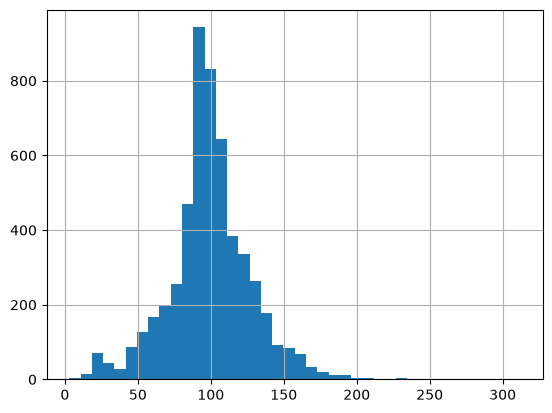

In [ ]:
# A histogram makes the shape of the distribution obvious at a glance.
runtime.hist(bins=40)

### Insight — movie runtime

* Mean **~99.3 min** vs median **~98 min** → the distribution is *nearly symmetric*,
  so the mean is trustworthy here (unlike price/revenue data, which is usually skewed).
* Range is extreme: **3 minutes to 312 minutes**. The 3-minute entries are short films
  and the 300+ minute entries are documentary compilations — both are legitimate content
  but they are **not "movies" in a programming sense**.
* The histogram shows a tight bell around 90–110 minutes: Netflix's movie slate is
  standard theatrical length.

### Recommendation
Introduce a **`format` dimension** (`Short < 40 min`, `Feature 40–150 min`,
`Extended > 150 min`) so that short films stop diluting "average movie runtime"
in reporting, and so the recommendation engine can treat a 3-minute short and a
2-hour feature as different products.

In [ ]:
# ---- TV SHOWS: season depth ---------------------------------------------------------
# We do NOT force a number here. The raw string ('1 Season', '2 Seasons', ...) is
# already the business answer, and value_counts() ranks it directly.
season_depth = netflix.loc[netflix['content_type'] == 'TV Show', 'duration'].value_counts()
season_depth.head(12)

duration
1 Season      1608
2 Seasons      382
3 Seasons      184
4 Seasons       87
5 Seasons       58
6 Seasons       30
7 Seasons       19
8 Seasons       18
9 Seasons        8
10 Seasons       6
11 Seasons       3
13 Seasons       2
Name: count, dtype: int64

In [ ]:
# What share of our TV catalogue is a ONE-AND-DONE season?
tv_total       = tv_only.shape[0]
single_season  = netflix.loc[(netflix['content_type'] == 'TV Show') &
                             (netflix['duration'] == '1 Season')].shape[0]

print('Total TV Shows      :', tv_total)
print('Single-season shows :', single_season)
print('Share single-season :', round(single_season / tv_total * 100, 1), '%')
print('Share renewed (2+)  :', round((tv_total - single_season) / tv_total * 100, 1), '%')

Total TV Shows      : 2410
Single-season shows : 1608
Share single-season : 66.7 %
Share renewed (2+)  : 33.3 %


### Insight — TV season depth

* **~1,608 of 2,410 TV Shows (67%) have only ONE season.**
* Only about **a third of series ever get renewed** to a second season.

### Recommendation
This is the most commercially loaded number in the notebook. A one-season show
delivers a burst of viewing and then stops producing retention value, while the
marketing spend to launch it is already sunk. Two actions:

1. Report a **"renewal rate" KPI** (share of series reaching S2) by genre and by country
   — it is a direct measure of commissioning quality.
2. Shift a slice of budget from *many* one-season bets to *fewer, longer-running*
   series in genres that historically renew, because multi-season shows are what
   convert a trial subscriber into a habitual one.

---
# STEP 7 — Content age: are we a premium service or a library?
---

In [ ]:
# release_year is already an integer, so we can do arithmetic directly.
# Create a new column from an existing one - the most common feature-engineering pattern.
CATALOGUE_SNAPSHOT_YEAR = 2021          # the year this export was taken
netflix['content_age'] = CATALOGUE_SNAPSHOT_YEAR - netflix['release_year']

print(netflix['release_year'].describe().round(1))
print()
print('Oldest title year :', netflix['release_year'].min())
print('Newest title year :', netflix['release_year'].max())
print('Median age (yrs)  :', netflix['content_age'].median())

count    7787.0
mean     2013.9
std         8.8
min      1925.0
25%      2013.0
50%      2017.0
75%      2018.0
max      2021.0
Name: release_year, dtype: float64

Oldest title year : 1925
Newest title year : 2021
Median age (yrs)  : 4.0


In [ ]:
# Bucket the catalogue into commercial freshness tiers using nested np.where.
netflix['freshness'] = np.where(netflix['content_age'] <= 2,  'Fresh (0-2 yrs)',
                       np.where(netflix['content_age'] <= 5,  'Recent (3-5 yrs)',
                       np.where(netflix['content_age'] <= 15, 'Catalogue (6-15 yrs)',
                                                             'Deep library (15+ yrs)')))

freshness_mix = netflix['freshness'].value_counts()
print(freshness_mix)
print()
print('Share (%):')
print((freshness_mix / netflix.shape[0] * 100).round(1))

freshness
Recent (3-5 yrs)          3015
Catalogue (6-15 yrs)      2132
Fresh (0-2 yrs)           1895
Deep library (15+ yrs)     745
Name: count, dtype: int64

Share (%):
freshness
Recent (3-5 yrs)          38.7
Catalogue (6-15 yrs)      27.4
Fresh (0-2 yrs)           24.3
Deep library (15+ yrs)     9.6
Name: count, dtype: float64


In [ ]:
# How many titles were released per year? sort_values on the index-derived column.
# We take the last 15 years to see the production ramp.
titles_per_year = netflix['release_year'].value_counts()

# sort_values() on the counts shows the biggest production years
print('Top 10 release years by number of titles in our catalogue:')
print(titles_per_year.sort_values(ascending=False).head(10))

Top 10 release years by number of titles in our catalogue:
release_year
2018    1121
2017    1012
2019     996
2016     882
2020     868
2015     541
2014     334
2013     267
2012     219
2010     173
Name: count, dtype: int64


### Insight — content age

* Median content age is **4 years**; the median release year is **2017**.
* Freshness tiers: **Fresh (0–2 yrs) 24.3%**, **Recent (3–5 yrs) 38.7%**,
  Catalogue (6–15 yrs) 27.4%, Deep library (15+ yrs) **9.6%**.
* So **~63% of the catalogue is 5 years old or newer** — the library is genuinely modern.
* Release years cluster hard in **2013–2018** (interquartile range), mirroring Netflix's
  originals ramp-up.
* The oldest title dates to **1925**, so a prestige/classic tail exists but is tiny (<10%).

### Recommendation
Netflix is correctly positioned as a **modern-content service, not a bargain library** —
but note that the *strictly* fresh tier (0–2 yrs) is only 24%, so the "brand-new content"
promise rests on a quarter of the shelf. Track **"share of catalogue ≤ 5 years old"**
(today 63%) as the monthly guardrail; it is the more stable metric, because the ≤ 2-year
band mechanically shrinks whenever a licensing cycle pauses. If the ≤ 5-year share slips
below ~55%, pricing power starts to erode.

---
# STEP 8 — Geography: where does our content come from?
---

In [ ]:
# `country` can hold MULTIPLE countries in one cell (co-productions), so
# value_counts() on the raw column counts co-production STRINGS, not countries.
# We look at it first anyway, because the single-country rows dominate.
top_country_strings = netflix['country'].value_counts()
top_country_strings.head(15)

country
United States     2555
India              923
United Kingdom     397
Japan              226
South Korea        183
Canada             177
Spain              134
France             115
Egypt              101
Mexico             100
Turkey             100
Australia           83
Taiwan              78
Brazil              72
Philippines         71
Name: count, dtype: int64

In [ ]:
# To count a country PROPERLY (including co-productions) we test for its presence
# inside the string using .str.contains(). This is the taught, correct approach.
# na=False tells Pandas to treat missing country values as 'not a match'
# instead of returning NaN, which would break the boolean mask.
key_markets = ['United States', 'India', 'United Kingdom', 'Japan', 'South Korea',
               'Canada', 'France', 'Spain', 'Mexico', 'Australia', 'Nigeria', 'Brazil']

market_rows = []
for market in key_markets:
    involved = netflix['country'].str.contains(market, na=False).sum()
    market_rows.append([market, involved, round(involved / netflix.shape[0] * 100, 1)])

# DataFrame() row-oriented constructor: a LIST OF ROWS + a list of column names.
market_footprint = pd.DataFrame(market_rows,
                                columns=['market', 'titles_involving_market', 'pct_of_catalogue'])
market_footprint = market_footprint.sort_values('titles_involving_market', ascending=False)
market_footprint

,market,titles_involving_market,pct_of_catalogue
0,United States,3297,42.3
1,India,990,12.7
2,United Kingdom,723,9.3
5,Canada,412,5.3
6,France,349,4.5
3,Japan,287,3.7
7,Spain,215,2.8
4,South Korea,212,2.7
8,Mexico,154,2.0
9,Australia,144,1.8


In [ ]:
# India deep-dive: what does our Indian slate actually look like?
india = netflix.loc[netflix['country'].str.contains('India', na=False)]

print('Total India-involved titles :', india.shape[0])
print()
print('Movie vs TV split in India:')
print(india['content_type'].value_counts())
print()
print('Audience mix in India (%):')
print((india['audience'].value_counts() / india.shape[0] * 100).round(1))
print()
print('Median content age - India :', india['content_age'].median(),
      'vs global', netflix['content_age'].median())

Total India-involved titles : 990

Movie vs TV split in India:
content_type
Movie      915
TV Show     75
Name: count, dtype: int64

Audience mix in India (%):
audience
Teen             55.7
Adult            25.4
Family           14.8
Kids              3.2
Unrated/Other     0.9
Name: count, dtype: float64

Median content age - India : 6.0 vs global 4.0


### Insight — geography

* **United States is involved in 3,297 titles (42.3%)** — the catalogue is still
  heavily US-centric.
* **India is the clear #2 market: 990 titles (12.7%)** — a genuinely material slate,
  ahead of the UK (723, 9.3%), Canada (412) and Japan (287).
* But the Indian slate is **film-shaped, not series-shaped**:
  **915 Movies vs only 75 TV Shows (92.4% movies)**. India supplies 17% of all Netflix
  movies but barely **3% of all TV Shows**.
* The Indian slate is also **older**: median content age **6 years vs 4 globally** —
  it leans on licensed Bollywood back-catalogue rather than fresh originals.
* Its audience mix is **Teen-dominant (55.7%)** versus Teen 29.8% globally — a direct
  reflection of the `TV-14`-heavy Indian film certification profile.
* ~6.5% of rows have no country at all, so all shares are **lower bounds**.

### Recommendation
1. **Commission Indian series, not just licence Indian films.** India is 12.7% of titles
   but only ~3% of TV Shows and its slate is 2 years older than the global median. This
   is the single largest structural gap found in the audit: the fastest-growing market is
   being served with the format that drives *acquisition* (film) rather than the one that
   drives *retention* (multi-season series).
2. **Refresh, don't just expand, the Indian catalogue.** A 6-year median age in a market
   this competitive on price is a churn risk.
3. Fix `country` capture at ingestion (6.5% blank). Market-share decisions worth
   hundreds of millions are being made on a column with a known 6.5% hole.

---
# STEP 9 — Genre demand mapping
---

In [ ]:
# `genres` is also multi-valued ('International TV Shows, TV Dramas, TV Sci-Fi & Fantasy'),
# so once again we count PRESENCE with .str.contains() rather than exact matches.
genre_list = ['Dramas', 'Comedies', 'Documentaries', 'Action & Adventure', 'Thrillers',
              'Romantic', 'Horror', 'Kids', 'Stand-Up Comedy', 'Crime',
              'Sci-Fi & Fantasy', 'Reality TV', 'Anime', 'Sports']

genre_rows = []
for g in genre_list:
    n = netflix['genres'].str.contains(g, na=False).sum()
    genre_rows.append([g, n, round(n / netflix.shape[0] * 100, 1)])

genre_profile = pd.DataFrame(genre_rows, columns=['genre', 'title_count', 'pct_of_catalogue'])
genre_profile = genre_profile.sort_values('title_count', ascending=False)
genre_profile

,genre,title_count,pct_of_catalogue
0,Dramas,2810,36.1
1,Comedies,1996,25.6
3,Action & Adventure,871,11.2
5,Romantic,864,11.1
2,Documentaries,786,10.1
4,Thrillers,541,6.9
9,Crime,427,5.5
7,Kids,414,5.3
6,Horror,381,4.9
8,Stand-Up Comedy,381,4.9


### Insight — genre

* **Dramas (2,810 titles, 36.1%)** and **Comedies (1,996, 25.6%)** are the backbone —
  together they touch over 60% of the catalogue.
* The second tier is tightly bunched: **Action & Adventure 871 (11.2%)**,
  **Romantic 864 (11.1%)**, **Documentaries 786 (10.1%)**. Documentaries punch above
  their weight on economics — cheap per hour and they travel across borders without dubbing.
* The **thin end is strikingly thin**: Reality TV **222 (2.9%)**, Anime **205 (2.6%)**,
  Sports **196 (2.5%)** — all well under a twentieth of the catalogue despite outsized
  cultural pull and, in Anime's case, a famously high-retention fanbase.

### Recommendation
**Reality/unscripted is the highest-ROI gap at 2.9%.** It is the cheapest renewable
format in television, it renews annually — which directly attacks the 66.7%
single-season problem found in Step 6 — and it localises without dubbing costs.
Recommend piloting 3–4 local unscripted formats per major market **before** greenlighting
another scripted drama, which at 36% is by far the most crowded shelf in the catalogue
and therefore the hardest place to be noticed.

---
# STEP 10 — When was content added? (proper date handling)
---

In [ ]:
# `added_on` is text like 'August 14, 2020'. to_datetime() converts it into a real
# datetime so that the .dt accessor unlocks year / month / day-name properties.
netflix['added_on'] = pd.to_datetime(netflix['added_on'], format='%B %d, %Y', errors='coerce')

print('dtype after conversion :', netflix['added_on'].dtype)
print('Earliest add date      :', netflix['added_on'].min())
print('Latest add date        :', netflix['added_on'].max())

dtype after conversion : datetime64[us]
Earliest add date      : 2008-01-01 00:00:00
Latest add date        : 2021-01-16 00:00:00


In [ ]:
# .dt gives the datetime properties of every value in the column at once.
netflix['added_year']  = netflix['added_on'].dt.year
netflix['added_month'] = netflix['added_on'].dt.month_name()
netflix['added_day']   = netflix['added_on'].dt.day_name()

netflix[['title', 'added_on', 'added_year', 'added_month', 'added_day']].head()

,title,added_on,added_year,added_month,added_day
0,3%,2020-08-14,2020.0,August,Friday
1,7:19,2016-12-23,2016.0,December,Friday
2,23:59,2018-12-20,2018.0,December,Thursday
3,9,2017-11-16,2017.0,November,Thursday
4,21,2020-01-01,2020.0,January,Wednesday


In [ ]:
# Content-acquisition velocity by year
adds_per_year = netflix['added_year'].value_counts().sort_values(ascending=False)
print('Titles added per year:')
print(adds_per_year.head(10))

Titles added per year:
added_year
2019.0    2136
2020.0    2008
2018.0    1661
2017.0    1201
2016.0     432
2021.0     117
2015.0      79
2014.0      24
2011.0      13
2013.0      10
Name: count, dtype: int64


In [ ]:
# Which weekday does Netflix prefer for releases? (a real programming decision)
print('Titles added by day of week:')
print(netflix['added_day'].value_counts())

Titles added by day of week:
added_day
Friday       2265
Thursday     1138
Tuesday      1055
Wednesday    1008
Monday        808
Saturday      718
Sunday        697
Name: count, dtype: int64


### Insight — acquisition cadence

* Additions accelerated steeply and then plateaued:
  **2017: 1,201 → 2018: 1,661 → 2019: 2,136 → 2020: 2,008**.
  2019 was the peak year; 2020 dipped slightly (COVID production shutdowns are the
  obvious candidate explanation, though this dataset cannot prove it).
* **Friday is overwhelmingly the biggest release day: 2,265 titles** — nearly *double*
  the next day (Thursday, 1,138). Tuesday (1,055) and Wednesday (1,008) follow.
* **The weekend itself is the quietest window**: Saturday 718 and Sunday 697 are the two
  lowest days.

### Recommendation
The pattern is deliberate and correct in intent — **drop on Friday so content is ready
for weekend binge viewing**, rather than dropping *during* the weekend. But Monday is
notably starved (808) and that is exactly when a weekly viewing habit needs a reason to
re-open the app. Recommend testing **Monday or Tuesday drops for episodic and unscripted
content** while reserving Friday for tentpole launches. This converts a once-a-week
engagement spike into a two-peak week without increasing content spend.

---
# STEP 11 — Row access patterns (`loc` vs `iloc`) for spot-checking records
---

Any analyst will be asked *"can you pull up that specific title?"* mid-meeting.
`loc` works on **labels**, `iloc` works on **positions**.

In [ ]:
# iloc -> POSITION based. iloc[0] is always the physically first row.
print('--- iloc[0] : first row by POSITION ---')
print(netflix.iloc[0][['title', 'content_type', 'release_year']])
print()

# loc -> LABEL based. Works on the index labels.
print('--- loc[0] : row with LABEL 0 ---')
print(netflix.loc[0][['title', 'content_type', 'release_year']])

--- iloc[0] : first row by POSITION ---
title                3%
content_type    TV Show
release_year       2020
Name: 0, dtype: object

--- loc[0] : row with LABEL 0 ---
title                3%
content_type    TV Show
release_year       2020
Name: 0, dtype: object


In [ ]:
# Rows AND columns together.
# iloc: end of the range is EXCLUSIVE (like normal Python slicing)
print('iloc[0:3, 0:4] -> rows 0,1,2 and columns 0,1,2,3')
print(netflix.iloc[0:3, 0:4])

iloc[0:3, 0:4] -> rows 0,1,2 and columns 0,1,2,3
  show_id content_type  title           director
0      s1      TV Show     3%                NaN
1      s2        Movie   7:19  Jorge Michel Grau
2      s3        Movie  23:59       Gilbert Chan


In [ ]:
# loc: end of the range is INCLUSIVE, and it uses column LABELS
print("loc[0:2, 'title':'country'] -> rows 0,1,2 (3 IS included)")
netflix.loc[0:2, 'title':'country']

loc[0:2, 'title':'country'] -> rows 0,1,2 (3 IS included)


,title,director,cast,country
0,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil
1,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico
2,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore


In [ ]:
# Non-consecutive rows and columns: pack the labels/positions in a list
netflix.iloc[[0, 100, 1000, 5000], [2, 1, 7, 9]]

,title,content_type,release_year,duration
0,3%,TV Show,2020,4 Seasons
100,3 Idiots,Movie,2009,164 min
1000,Blue Planet II,TV Show,2017,1 Season
5000,Pukar,Movie,2000,165 min


In [ ]:
# set_index() lets us look a title up by name instead of by row number -
# exactly what you want when a stakeholder names a show in a meeting.
by_title = netflix.set_index('title')
by_title.loc['3%', ['content_type', 'country', 'release_year', 'duration', 'genres']]

content_type                                              TV Show
country                                                    Brazil
release_year                                                 2020
duration                                                4 Seasons
genres          International TV Shows, TV Dramas, TV Sci-Fi &...
Name: 3%, dtype: object

---
# STEP 12 — Prolific suppliers (and why we must caveat this table)
---

In [ ]:
# The classic 'top directors' request. We answer it - but honestly.
top_directors = netflix['director'].value_counts()

print('Top 10 directors by number of titles:')
print(top_directors.head(10))
print()
print('IMPORTANT CAVEAT')
print('Titles WITH a director    :', netflix['director'].count())
print('Titles WITHOUT a director :', netflix['director'].isnull().sum())
print('Coverage                  :', round(netflix['director'].count() / netflix.shape[0] * 100, 1), '%')

Top 10 directors by number of titles:
director
Raúl Campos, Jan Suter    18
Marcus Raboy              16
Jay Karas                 14
Cathy Garcia-Molina       13
Youssef Chahine           12
Martin Scorsese           12
Jay Chapman               12
Steven Spielberg          10
David Dhawan               9
Kunle Afolayan             8
Name: count, dtype: int64

IMPORTANT CAVEAT
Titles WITH a director    : 5398
Titles WITHOUT a director : 2389
Coverage                  : 69.3 %


In [ ]:
# Is the missingness RANDOM or STRUCTURAL? This is the question that decides whether
# the leaderboard above is merely incomplete or actively misleading.
movie_missing = netflix.loc[netflix['content_type'] == 'Movie', 'director'].isnull().sum()
tv_missing    = netflix.loc[netflix['content_type'] == 'TV Show', 'director'].isnull().sum()

print('MOVIES   : missing director =', movie_missing, 'of', movies_only.shape[0],
      '->', round(movie_missing / movies_only.shape[0] * 100, 1), '%')
print('TV SHOWS : missing director =', tv_missing, 'of', tv_only.shape[0],
      '->', round(tv_missing / tv_only.shape[0] * 100, 1), '%')

MOVIES   : missing director = 163 of 5377 -> 3.0 %
TV SHOWS : missing director = 2226 of 2410 -> 92.4 %


### Insight — supplier concentration

* The top credit (`Raúl Campos, Jan Suter`) has only **18 titles out of 7,787 = 0.23%**.
  Even Spielberg and Scorsese sit at 10–12 titles. There is **no supplier concentration
  risk** — the catalogue is extremely fragmented, which is healthy: no single creative
  partner can hold Netflix hostage at renewal.
* **The missingness is structural, not random** — and this is the important part.
  The `director` field is blank for only **3.0% of Movies (163 of 5,377)** but for
  **92.4% of TV Shows (2,226 of 2,410)** — because a series credits a *showrunner*,
  not a director.
* Therefore the leaderboard above is not merely 69% complete — it is **an almost
  pure-Movies ranking**. Presenting it as "top Netflix creators" would silently erase the
  entire television slate.

### Recommendation
1. **Never publish this table as "top creators."** Label it explicitly as
   *"top film directors, movies only"*.
2. Create a separate **`creator` field** that stores showrunner for series and director
   for film, so TV Shows stop being invisible in supplier analysis.
3. This is also a lesson in method: always test *whether* missing data is random before
   deciding whether an analysis is usable. A 30% hole spread evenly is an inconvenience;
   a 30% hole concentrated in one segment is a **wrong answer waiting to be presented**.

---
# STEP 13 — Building the Content Scorecard from scratch
---

The final deliverable: a single small table the VP can paste into a board deck.
We build it with the `pd.DataFrame()` constructor.

In [ ]:
# Compute every KPI first, so the scorecard is readable and auditable.
total_titles     = netflix.shape[0]
n_movies         = netflix.loc[netflix['content_type'] == 'Movie'].shape[0]
n_tv             = netflix.loc[netflix['content_type'] == 'TV Show'].shape[0]
pct_fresh        = round(netflix.loc[netflix['freshness'] == 'Fresh (0-2 yrs)'].shape[0] / total_titles * 100, 1)
pct_kids_family  = round(netflix.loc[netflix['audience'].isin(['Kids', 'Family'])].shape[0] / total_titles * 100, 1)
pct_adult        = round(netflix.loc[netflix['audience'] == 'Adult'].shape[0] / total_titles * 100, 1)
median_age       = netflix['content_age'].median()
mean_runtime     = round(netflix.loc[movie_mask, 'runtime_min'].mean(), 1)
pct_single_seas  = round(single_season / n_tv * 100, 1)
n_countries_us   = netflix['country'].str.contains('United States', na=False).sum()
pct_us           = round(n_countries_us / total_titles * 100, 1)
pct_india        = round(netflix['country'].str.contains('India', na=False).sum() / total_titles * 100, 1)
director_cov     = round(netflix['director'].count() / total_titles * 100, 1)

pct_within_5yr   = round(netflix.loc[netflix['content_age'] <= 5].shape[0] / total_titles * 100, 1)
pct_kids_movies  = round(netflix.loc[(netflix['content_type'] == 'Movie') &
                                     (netflix['audience'] == 'Kids')].shape[0] / n_movies * 100, 1)
india_tv_share   = round(netflix.loc[(netflix['country'].str.contains('India', na=False)) &
                                     (netflix['content_type'] == 'TV Show')].shape[0] / n_tv * 100, 1)

scorecard = pd.DataFrame({
    'metric': ['Total titles',
               'Movies',
               'TV Shows',
               'Movie share of catalogue (%)',
               'Fresh content, 0-2 yrs old (%)',
               'Content 5 yrs old or newer (%)',
               'Median content age (years)',
               'Kids + Family share, all formats (%)',
               'Kids-rated share of MOVIES only (%)',
               'Adult-rated share (%)',
               'Mean movie runtime (min)',
               'TV Shows with only 1 season (%)',
               'Titles involving USA (%)',
               'Titles involving India (%)',
               'India share of all TV Shows (%)',
               'Director field coverage (%)'],
    'value':  [total_titles,
               n_movies,
               n_tv,
               round(n_movies / total_titles * 100, 1),
               pct_fresh,
               pct_within_5yr,
               median_age,
               pct_kids_family,
               pct_kids_movies,
               pct_adult,
               mean_runtime,
               pct_single_seas,
               pct_us,
               pct_india,
               india_tv_share,
               director_cov]
})

# Add a health flag so the board can read it without asking questions.
scorecard['flag'] = ['-', '-', '-', 'WATCH', 'WATCH', 'GOOD', 'GOOD', 'WATCH',
                     'RISK', 'WATCH', '-', 'RISK', 'WATCH', 'GOOD', 'RISK', 'RISK']
scorecard

,metric,value,flag
0,Total titles,7787.0,-
1,Movies,5377.0,-
2,TV Shows,2410.0,-
3,Movie share of catalogue (%),69.1,WATCH
4,"Fresh content, 0-2 yrs old (%)",24.3,WATCH
5,Content 5 yrs old or newer (%),63.1,GOOD
6,Median content age (years),4.0,GOOD
7,"Kids + Family share, all formats (%)",23.7,WATCH
8,Kids-rated share of MOVIES only (%),6.8,RISK
9,Adult-rated share (%),45.3,WATCH


In [ ]:
# Re-index the scorecard to start at 1 instead of 0 - board decks do not start at row zero.
# np.arange builds the new label sequence.
scorecard.index = np.arange(1, scorecard.shape[0] + 1, dtype=np.int32)
scorecard

,metric,value,flag
1,Total titles,7787.0,-
2,Movies,5377.0,-
3,TV Shows,2410.0,-
4,Movie share of catalogue (%),69.1,WATCH
5,"Fresh content, 0-2 yrs old (%)",24.3,WATCH
6,Content 5 yrs old or newer (%),63.1,GOOD
7,Median content age (years),4.0,GOOD
8,"Kids + Family share, all formats (%)",23.7,WATCH
9,Kids-rated share of MOVIES only (%),6.8,RISK
10,Adult-rated share (%),45.3,WATCH


In [ ]:
# Export the deliverables so they can be attached to the planning pack.
scorecard.to_csv('netflix_content_scorecard.csv', sep=',')
quality.to_csv('netflix_data_quality_report.csv', sep=',')
market_footprint.to_csv('netflix_market_footprint.csv', sep=',')
genre_profile.to_csv('netflix_genre_profile.csv', sep=',')

print('Exported 4 CSV deliverables.')
print('In Colab these appear in the file browser on the left (/content/).')

Exported 4 CSV deliverables.
In Colab these appear in the file browser on the left (/content/).


---
# STEP 14 — EXECUTIVE SUMMARY
---

## What we found

| # | Finding | Number | So what? |
|---|---|---|---|
| 1 | Catalogue is movie-heavy by title count | 5,377 Movies (69.1%) / 2,410 TV (30.9%) | Title count misleads; on an hours-of-content basis TV almost certainly dominates |
| 2 | Two-thirds of series never get a second season | **66.7% single-season** (1,608 of 2,410) | Commissioning-quality problem — retention value evaporates after S1 |
| 3 | Kids/family gap is in **film**, not series | Kids = **6.8% of movies** vs 17.6% of TV | "Family movie night" has a thin shelf; the blended 23.6% figure hides it |
| 4 | Catalogue is modern but the "brand new" tier is narrow | 63% ≤ 5 yrs, only **24.3% ≤ 2 yrs**, median age 4 | Positioning is defensible, but freshness rests on a quarter of the shelf |
| 5 | India is #2 in supply yet almost absent from TV | 990 titles (12.7%) but **only 3% of all TV Shows**; median age 6 vs 4 | Growth market served with the acquisition format, not the retention format |
| 6 | `director` is unusable for reporting | **30.68% missing** (2,389 rows) | Every supplier dashboard in the company runs on biased data |
| 7 | Release cadence spikes hard on Friday | **Friday 2,265** vs Thursday 1,138; Mon 808 | One engagement peak per week; Monday is starved |
| 8 | No supplier concentration risk | Top credit = 18 titles = **0.23%** | Healthy fragmentation; no single point of failure |
| 9 | Unscripted is the thinnest major format | Reality TV **2.9%**, Anime 2.6%, Sports 2.5% | The cheapest renewable format is the least stocked |

## Recommendations, ranked by commercial impact

1. **Fix the renewal problem before buying more titles.** 66.7% single-season means the
   organisation repeatedly pays launch marketing for assets that stop working after one
   season. Introduce a **renewal-rate KPI by genre and market** and reallocate budget
   from breadth to depth.
2. **Commission Indian series.** India is 12.7% of titles but ~3% of TV Shows, and its
   slate is 2 years older than the global median. This is the largest structural gap in
   the audit — and it sits in the company's most important growth market.
3. **Build a kids & family FILM slate.** Kids-rated content is 17.6% of series but only
   **6.8% of movies**. Stop letting the healthy kids-series position mask the weak
   family-movie shelf; report Kids/Family share split by format from now on.
4. **Invest in local unscripted/reality formats (today just 2.9%).** Cheapest renewable
   format; it directly attacks both the renewal problem (#1) and the Monday engagement
   trough (#7), and it localises without dubbing cost.
5. **Quarantine `director` from dashboards and add a `creator` field** that captures
   showrunner for series and director for film. Publish field coverage as a visible
   data-quality KPI rather than letting a 31% hole sit silently inside executive reporting.
6. **Guard freshness on the ≤ 5-year metric (today 63%), not the ≤ 2-year one.** The
   2-year band mechanically shrinks whenever a licensing cycle pauses, so it triggers
   false alarms. Escalate if ≤ 5-year share falls below ~55%.
7. **Test mid-week drops.** Move episodic and unscripted releases to Monday/Tuesday and
   keep Friday for tentpoles — a two-peak week at zero incremental content cost.

## Assumptions and limitations (state these — it is what separates an analyst from a report generator)

* The export is a **snapshot dated early 2021**; it is not a live catalogue feed.
* `country` is blank for 6.5% of rows, so all market shares are **lower bounds**.
* `duration` for TV Shows counts **seasons, not hours**, so cross-format comparison is
  directional only.
* We have **no viewing, revenue or subscriber data** — every retention claim here is a
  reasoned hypothesis about content supply, not a measured outcome. The obvious next
  step is to join this catalogue to watch-time data.